
# HAH913E-2026-Projet-C

## Influence de l'utilisation du téléphone sur le mouvement pendant la marche

**UE HAH913E – Physical Activity for Health**

**Participants :** Tania FARAJ, Thomas VIGNEAU SUGAR et Sarah MUSSOTTE

### Objectif
Étudier l'influence de l'utilisation du téléphone pendant la marche sur l'intensité du mouvement à partir de données d'accélérométrie enregistrées avec un capteur Axivity AX3.

### Problématique
Écrire un message sur son téléphone pendant la marche modifie-t-il l'intensité du mouvement ?

### Hypothèse
L'utilisation du téléphone pendant la marche entraîne une diminution de l'intensité du mouvement, observable par une diminution de l'ENMO moyen.


### Importation des bibliothèques et des données

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Définition des dossiers du projet
DOSSIER_DATA = Path("data")
DOSSIER_RESULTS = Path("results")
DOSSIER_FIGURES = DOSSIER_RESULTS / "figures"

# Création des dossiers de résultats s'ils n'existent pas
DOSSIER_FIGURES.mkdir(parents=True, exist_ok=True)

print("Bibliothèques importées avec succès.")
print("Dossier de données :", DOSSIER_DATA.resolve())

Bibliothèques importées avec succès.
Dossier de données : C:\Users\sarah\Documents\Master\M2\5-Santé_activité_physique\2-Physical-activity-assigment-project\HAH913E-2026-Projet-C\data


In [2]:
# Liste des participants et des fichiers associés

participants = {
    "Tania": {
        "sans_tel": "Tania-sans-tel.csv",
        "avec_tel": "Tania-avec-tel.csv"
    },
    "Thomas": {
        "sans_tel": "Thomas-sans-tel.csv",
        "avec_tel": "Thomas-avec-tel.csv"
    },
    "Sarah": {
        "sans_tel": "Sarah-sans-tel.csv",
        "avec_tel": "Sarah-avec-tel.csv"
    }
}

# Importation des données
donnees = {}

for participant, fichiers in participants.items():

    donnees[participant] = {}

    for condition, fichier in fichiers.items():

        chemin = DOSSIER_DATA / fichier

        df = pd.read_csv(
            chemin,
            header=None,
            names=["Time", "X", "Y", "Z"]
        )

        df["Time"] = pd.to_datetime(df["Time"])

        donnees[participant][condition] = df

        print(
            participant,
            condition,
            ":",
            len(df),
            "mesures importées"
        )

Tania sans_tel : 20640 mesures importées
Tania avec_tel : 20640 mesures importées
Thomas sans_tel : 27000 mesures importées
Thomas avec_tel : 20880 mesures importées
Sarah sans_tel : 20160 mesures importées
Sarah avec_tel : 24840 mesures importées


### Vérification de la qualité des données

In [3]:
# Vérification des données des trois participants

for participant in donnees:

    print("\n------------------------------")
    print("PARTICIPANT :", participant)
    print("------------------------------")

    for condition in ["sans_tel", "avec_tel"]:

        df = donnees[participant][condition]

        duree = (
            df["Time"].iloc[-1] - df["Time"].iloc[0]
        ).total_seconds()

        frequence = len(df) / duree

        valeurs_manquantes = df[["X", "Y", "Z"]].isna().sum().sum()

        print("\nCondition :", condition)
        print("Nombre de mesures :", len(df))
        print("Durée :", round(duree, 2), "secondes")
        print("Fréquence :", round(frequence, 2), "Hz")
        print("Valeurs manquantes :", valeurs_manquantes)


------------------------------
PARTICIPANT : Tania
------------------------------

Condition : sans_tel
Nombre de mesures : 20640
Durée : 210.15 secondes
Fréquence : 98.22 Hz
Valeurs manquantes : 0

Condition : avec_tel
Nombre de mesures : 20640
Durée : 210.14 secondes
Fréquence : 98.22 Hz
Valeurs manquantes : 0

------------------------------
PARTICIPANT : Thomas
------------------------------

Condition : sans_tel
Nombre de mesures : 27000
Durée : 274.81 secondes
Fréquence : 98.25 Hz
Valeurs manquantes : 0

Condition : avec_tel
Nombre de mesures : 20880
Durée : 212.69 secondes
Fréquence : 98.17 Hz
Valeurs manquantes : 0

------------------------------
PARTICIPANT : Sarah
------------------------------

Condition : sans_tel
Nombre de mesures : 20160
Durée : 205.19 secondes
Fréquence : 98.25 Hz
Valeurs manquantes : 0

Condition : avec_tel
Nombre de mesures : 24840
Durée : 252.97 secondes
Fréquence : 98.19 Hz
Valeurs manquantes : 0


### Calculer l'ENMO
On reprend la formule utilisée dans vos trois notebooks.

\[
$
ENMO=\max\left(\sqrt{X^2+Y^2+Z^2}-1,0\right)\times1000
$
\]

In [4]:
def calcul_enmo(df):
    
    df = df.copy()

    norme = np.sqrt(
        df["X"]**2 +
        df["Y"]**2 +
        df["Z"]**2
    )

    df["ENMO"] = np.maximum(norme - 1, 0) * 1000

    return df


# Calcul de l'ENMO pour les six enregistrements

for participant in donnees:

    for condition in ["sans_tel", "avec_tel"]:

        donnees[participant][condition] = calcul_enmo(
            donnees[participant][condition]
        )

print("Calcul de l'ENMO terminé pour les trois participants.")

Calcul de l'ENMO terminé pour les trois participants.


### Définir les périodes de marche réelle

In [6]:
# Début et fin des périodes de marche (en secondes)

periodes = {
    "Tania": {
        "sans_tel": (52, 172),
        "avec_tel": (56, 176)
    },
    "Thomas": {
        "sans_tel": (94, 214),
        "avec_tel": (52, 172)
    },
    "Sarah": {
        "sans_tel": (50, 170),
        "avec_tel": (60, 180)
    }
}

DUREE_MARCHE = 120
DUREE_FENETRE = 10

print("Périodes de marche définies.")

Périodes de marche définies.


### Fonction d'analyse de l'ENMO
Cette fonction réalise le traitement principal :
- Sélection de la période réelle de marche.
- Découpage en fenêtres de 10 secondes.
- Calcul de l'ENMO moyen, de son écart-type et du nombre de mesures par fenêtre.

In [7]:
def analyse_condition(df, debut, fin):
    
    # Temps écoulé depuis le début de l'enregistrement
    temps = (
        df["Time"] - df["Time"].iloc[0]
    ).dt.total_seconds()

    # Sélection de la période analysée
    debut_analyse = debut
    fin_analyse = fin

    masque = (
        (temps >= debut_analyse) &
        (temps < fin_analyse)
    )

    donnees_marche = df.loc[masque].copy()

    if donnees_marche.empty:
        raise ValueError("Aucune donnée dans la période sélectionnée.")

    # Temps relatif au début de l'analyse
    donnees_marche["Temps_relatif"] = (
        temps.loc[masque] - debut_analyse
    )

    # Création des fenêtres de 10 secondes
    donnees_marche["Fenetre"] = (
        np.floor(
            donnees_marche["Temps_relatif"] / DUREE_FENETRE
        ).astype(int)
    )

    # Calcul des statistiques par fenêtre
    resultats = donnees_marche.groupby("Fenetre").agg(
        ENMO_moyen=("ENMO", "mean"),
        ENMO_ecart_type=("ENMO", "std"),
        Nombre_mesures=("ENMO", "count")
    )

    return resultats, donnees_marche

### Analyse des trois participants

In [8]:
resultats = {}

for participant in donnees:

    resultats[participant] = {}

    for condition in ["sans_tel", "avec_tel"]:

        debut, fin = periodes[participant][condition]

        tableau, donnees_marche = analyse_condition(
            donnees[participant][condition],
            debut,
            fin
        )

        resultats[participant][condition] = tableau

        print("\n", participant, "-", condition)
        display(tableau)


 Tania - sans_tel


,ENMO_moyen,ENMO_ecart_type,Nombre_mesures
Fenetre,,,
0,622.103723,904.021713,981
1,556.186405,726.913127,982
2,542.208333,705.878795,982
3,577.861404,755.778571,982
4,620.175071,752.232300,982
5,608.161292,775.104938,982
6,605.114303,759.370297,983
7,580.406583,725.024189,982
8,594.065664,739.343281,982



 Tania - avec_tel


,ENMO_moyen,ENMO_ecart_type,Nombre_mesures
Fenetre,,,
0,446.838456,802.476829,982
1,401.127169,570.316055,981
2,341.216658,474.959730,982
3,383.013462,543.791094,982
4,403.682687,566.019959,982
5,378.929939,544.417650,983
6,371.661309,518.120625,982
7,289.671098,457.191109,983
8,352.426158,485.012508,982



 Thomas - sans_tel


,ENMO_moyen,ENMO_ecart_type,Nombre_mesures
Fenetre,,,
0,468.661306,917.501525,981
1,428.258417,535.946947,983
2,406.826255,532.394929,981
3,441.338848,562.117753,983
4,419.128214,552.805368,983
5,424.805099,533.258941,982
6,406.217041,553.276702,983
7,434.082986,545.070325,983
8,443.038155,565.053074,982


... (2 outputs left out)


 Sarah - sans_tel


,ENMO_moyen,ENMO_ecart_type,Nombre_mesures
Fenetre,,,
0,522.139889,746.936085,981
1,519.716025,638.455813,983
2,534.545534,651.754759,983
3,515.345522,666.189338,981
4,499.344698,658.548154,983
5,505.593118,630.184647,982
6,469.732303,614.254336,983
7,514.812422,669.053458,983
8,448.494694,604.049007,982



 Sarah - avec_tel


,ENMO_moyen,ENMO_ecart_type,Nombre_mesures
Fenetre,,,
0,407.801251,583.276925,982
1,348.136432,447.094446,981
2,390.917684,502.053228,981
3,386.373058,497.763267,982
4,381.425998,523.391641,982
5,322.701343,423.391671,981
6,357.871343,465.115621,982
7,305.227268,411.238148,982
8,327.280009,430.375860,982


### Calculer les moyennes et les variations individuelles

In [9]:
synthese = []

for participant in resultats:

    moyenne_sans = (
        resultats[participant]["sans_tel"]["ENMO_moyen"].mean()
    )

    moyenne_avec = (
        resultats[participant]["avec_tel"]["ENMO_moyen"].mean()
    )

    variation = (
        (moyenne_avec - moyenne_sans) / moyenne_sans
    ) * 100

    synthese.append({
        "Participant": participant,
        "Sans téléphone (mg)": moyenne_sans,
        "Avec téléphone (mg)": moyenne_avec,
        "Variation (%)": variation
    })

tableau_synthese = pd.DataFrame(synthese)

display(
    tableau_synthese.round(2)
)

,Participant,Sans téléphone (mg),Avec téléphone (mg),Variation (%)
0,Tania,582.97,363.17,-37.70
1,Thomas,426.74,403.51,-5.44
2,Sarah,504.18,350.14,-30.55


### Graphique comparatif individuel
On va afficher l'évolution de l'ENMO moyen sur les dix fenêtres de chaque participant.

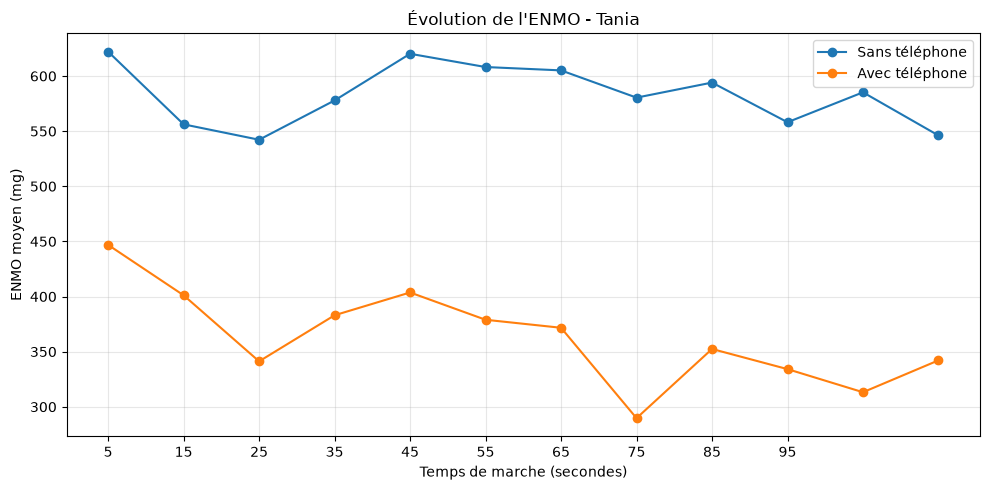

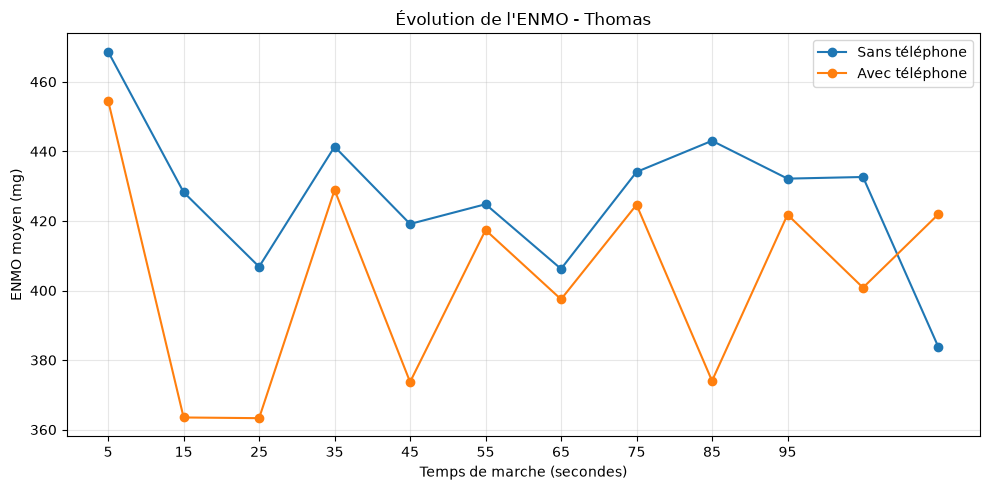

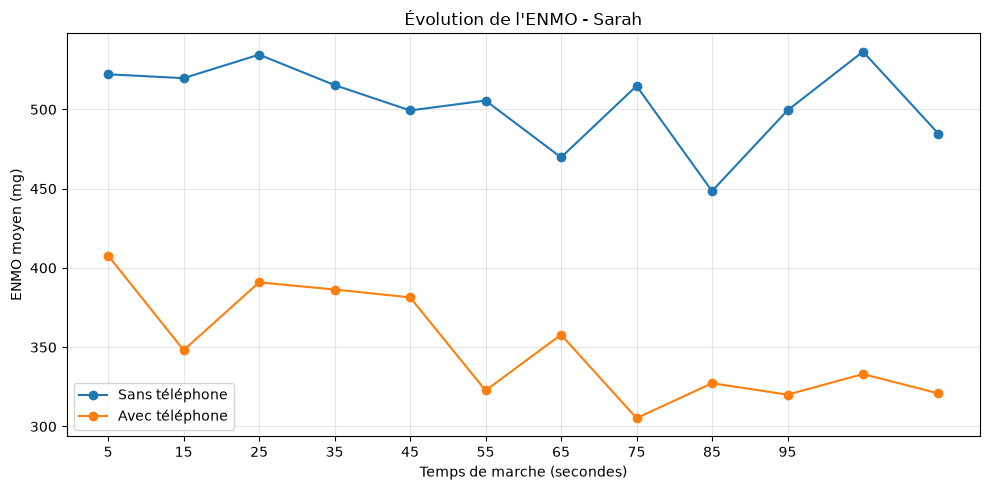

In [11]:
for participant in resultats:
    
    plt.figure(figsize=(10, 5))

    for condition, label in [
        ("sans_tel", "Sans téléphone"),
        ("avec_tel", "Avec téléphone")
    ]:

        valeurs = resultats[participant][condition]["ENMO_moyen"]

        temps = np.arange(len(valeurs)) * 10 + 5

        plt.plot(
            temps,
            valeurs.values,
            marker="o",
            label=label
        )

    plt.xlabel("Temps de marche (secondes)")
    plt.ylabel("ENMO moyen (mg)")
    plt.title(f"Évolution de l'ENMO - {participant}")

    plt.xticks(np.arange(5, 101, 10))
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        DOSSIER_FIGURES / f"Evolution_ENMO_{participant}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

### Boxplots: Diagrammes en boîtes à moustaches
Comparaison des valeurs moyennes et médianes, de la distribution des données et des écrats types. 

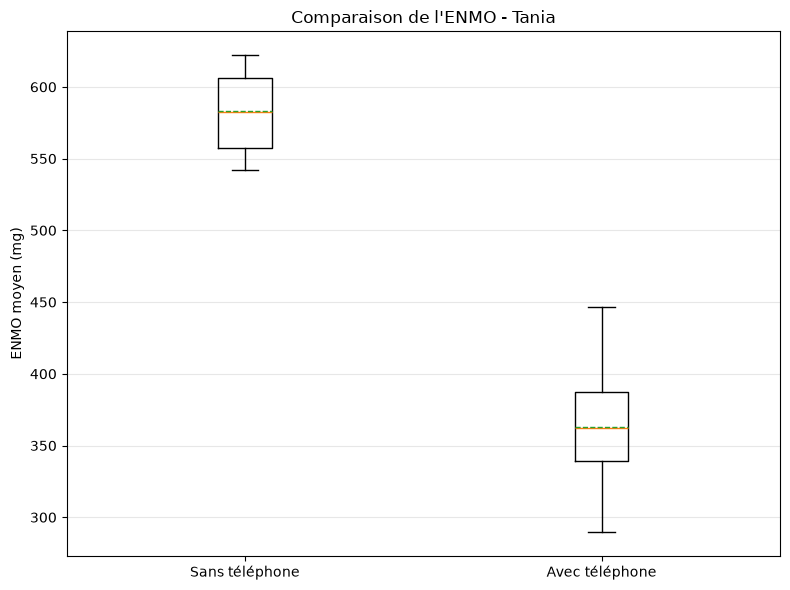

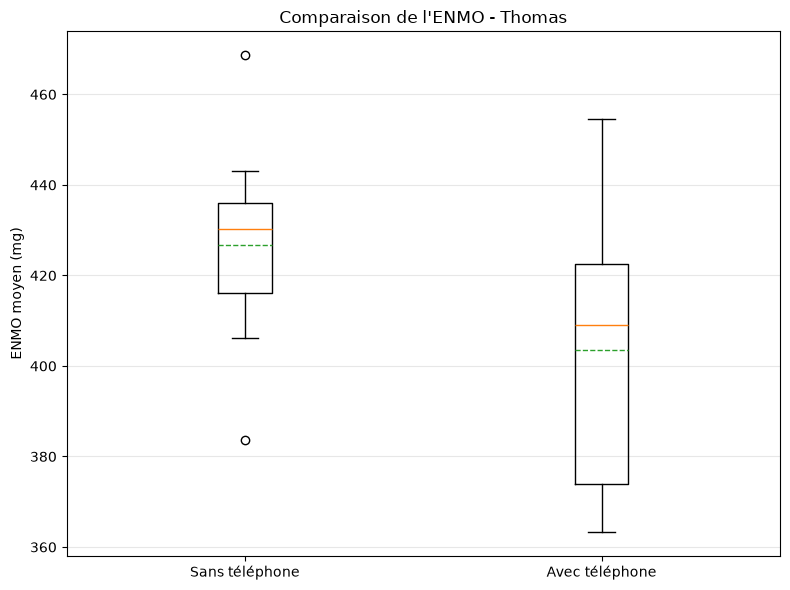

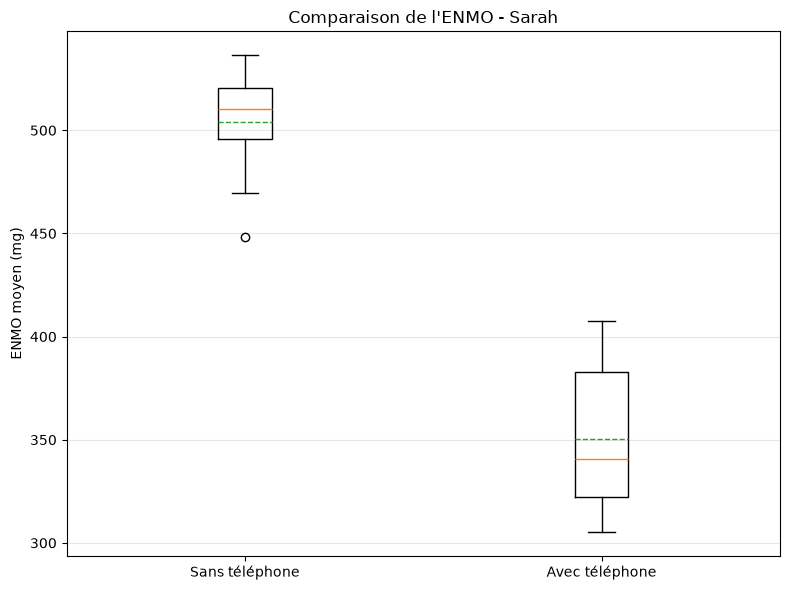

In [16]:
for participant in resultats:
    
    plt.figure(figsize=(8, 6))

    donnees_boxplot = [
        resultats[participant]["sans_tel"]["ENMO_moyen"],
        resultats[participant]["avec_tel"]["ENMO_moyen"]
    ]

    plt.boxplot(
        donnees_boxplot,
        showmeans=True,
        meanline=True
    )
    
    plt.xticks([1, 2],
               ["Sans téléphone", "Avec téléphone"])

    plt.ylabel("ENMO moyen (mg)")
    plt.title(f"Comparaison de l'ENMO - {participant}")

    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        DOSSIER_FIGURES / f"Boxplot_ENMO_{participant}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

### Comparaison collective

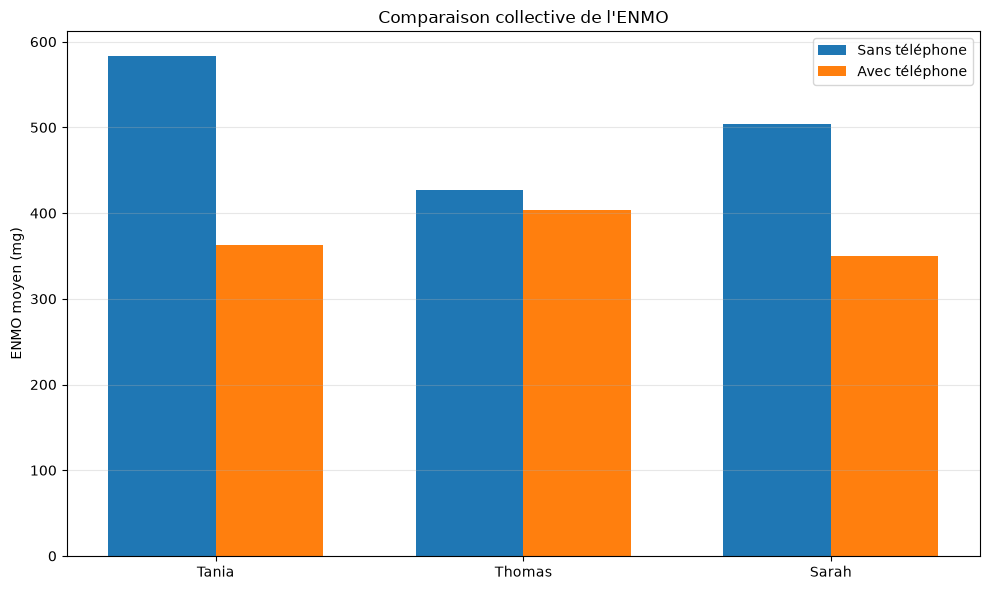

Tableau de synthèse enregistré.


In [18]:
# Comparaison des moyennes des trois participants

plt.figure(figsize=(10, 6))

x = np.arange(len(tableau_synthese))
largeur = 0.35

plt.bar(
    x - largeur/2,
    tableau_synthese["Sans téléphone (mg)"],
    largeur,
    label="Sans téléphone"
)

plt.bar(
    x + largeur/2,
    tableau_synthese["Avec téléphone (mg)"],
    largeur,
    label="Avec téléphone"
)

plt.xticks(x, tableau_synthese["Participant"])

plt.ylabel("ENMO moyen (mg)")
plt.title("Comparaison collective de l'ENMO")

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    DOSSIER_FIGURES / "Comparaison_collective_ENMO.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

tableau_synthese.to_csv(
    DOSSIER_RESULTS / "synthese_ENMO.csv",
    index=False
)

print("Tableau de synthèse enregistré.")